# 02 — Qiskit Aer: quantum circuit simulation on CPUs and GPUs

> **Container note.** The container (`qiskit.sif`) builds `qiskit-aer` 0.17.2 from source with CUDA.
> `device="GPU"` needs a GPU node and `apptainer exec --nv`.

**Qiskit Aer** is the simulator package for Qiskit [[1]](https://qiskit.github.io/qiskit-aer/getting_started.html). It provides:

* `AerSimulator`, a Qiskit backend (`BackendV2`) with several simulation methods: statevector, density matrix, stabilizer, matrix product state and others.
* Noise models for realistic simulation.
* GPU acceleration through NVIDIA CUDA and the cuStateVec library [[2]](https://docs.nvidia.com/cuda/cuquantum/latest/custatevec/index.html).
* Aer versions of the Qiskit primitives `SamplerV2` and `EstimatorV2`.

**Based on**

* Qiskit Aer documentation, <https://qiskit.github.io/qiskit-aer/>: Getting started [[1]](https://qiskit.github.io/qiskit-aer/getting_started.html)
* Aer tutorials: Simulators [[3]](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html), Device backend noise model simulations [[4]](https://qiskit.github.io/qiskit-aer/tutorials/2_device_noise_simulation.html), Building noise models [[5]](https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html), Matrix product state simulation method [[6]](https://qiskit.github.io/qiskit-aer/tutorials/7_matrix_product_state_method.html)
* Aer how-to guides: Running with threadpool [[7]](https://qiskit.github.io/qiskit-aer/howtos/parallel.html), Running with multiple GPUs and/or multiple nodes [[8]](https://qiskit.github.io/qiskit-aer/howtos/running_gpu.html)
* GPU and cuStateVec: the `AerSimulator` API reference [[9]](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html), the Aer GPU build instructions [[10]](https://github.com/Qiskit/qiskit-aer/blob/main/CONTRIBUTING.md) and the NVIDIA cuStateVec documentation [[2]](https://docs.nvidia.com/cuda/cuquantum/latest/custatevec/index.html)

**Contents**
1. Setup and version check
2. `AerSimulator` basics: shots, seeds, counts
3. Simulation methods (automatic, statevector, density_matrix, stabilizer, matrix_product_state, unitary)
4. Devices: detecting a GPU and falling back to CPU
5. Save instructions: `save_statevector`, `save_expectation_value`, ...
6. Aer primitives: `SamplerV2` and `EstimatorV2`
7. Noise models: depolarizing, thermal relaxation, readout error
8. `NoiseModel.from_backend` with a fake IBM backend
9. Noisy vs ideal GHZ states
10. Large Clifford circuits: stabilizer and MPS methods
11. Performance options (CPU and GPU)
12. Summary and references

## 1. Setup and version check

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

print("qiskit     :", qiskit.__version__)
print("qiskit-aer :", qiskit_aer.__version__, "(loaded from", qiskit_aer.__file__.rsplit('/qiskit_aer', 1)[0] + ")")

qiskit     : 2.5.2
qiskit-aer : 0.17.2 (loaded from /opt/venv/lib/python3.10/site-packages)


## 2. `AerSimulator` basics: shots, seeds and counts

`AerSimulator` is a normal Qiskit backend [[3]](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html). We transpile the circuit for it, call `run(...)` and read the `Result`.

* `shots` is the number of samples (default 1024).
* `seed_simulator` makes the sampling reproducible. Give it to `run()` or set it as a backend option.

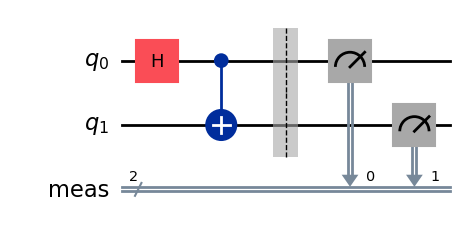

seed 1234: {'00': 1001, '11': 999}
seed 1234: {'00': 1001, '11': 999} -> identical: True
seed  999: {'00': 984, '11': 1016}


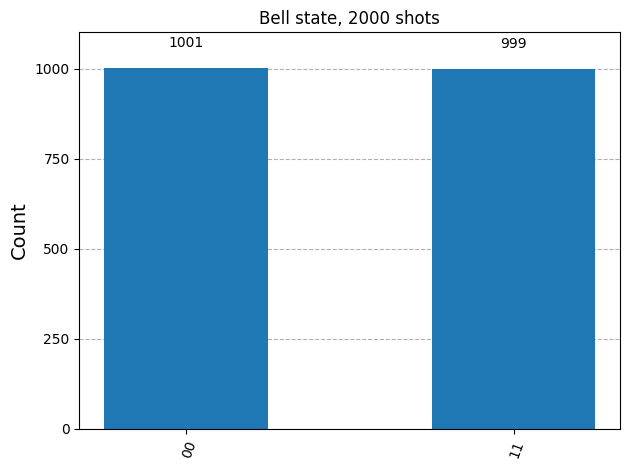

In [2]:
bell = QuantumCircuit(2, name="bell")
bell.h(0)
bell.cx(0, 1)
bell.measure_all()
display(bell.draw("mpl"))

sim = AerSimulator()
tbell = transpile(bell, sim)

r1 = sim.run(tbell, shots=2000, seed_simulator=1234).result().get_counts()
r2 = sim.run(tbell, shots=2000, seed_simulator=1234).result().get_counts()
r3 = sim.run(tbell, shots=2000, seed_simulator=999).result().get_counts()
print("seed 1234:", r1)
print("seed 1234:", r2, "-> identical:", r1 == r2)
print("seed  999:", r3)
plot_histogram(r1, title="Bell state, 2000 shots")

`get_memory()` returns the outcome of each single shot. It needs `memory=True` in `run()`.

One job can run several circuits. The results are indexed by the position of the circuit in the list.

In [3]:
res = sim.run(tbell, shots=8, memory=True, seed_simulator=7).result()
print("per-shot memory:", res.get_memory())

ghz3 = QuantumCircuit(3); ghz3.h(0); ghz3.cx(0, 1); ghz3.cx(1, 2); ghz3.measure_all()
job = sim.run(transpile([bell, ghz3], sim), shots=500, seed_simulator=1)
for i, c in enumerate(job.result().get_counts()):
    print(f"circuit {i}:", c)
print("method actually used:", job.result().results[1].metadata["method"])

per-shot memory: ['11', '00', '11', '00', '11', '00', '00', '11']


circuit 0: {'11': 248, '00': 252}
circuit 1: {'000': 244, '111': 256}
method actually used: stabilizer


## 3. Simulation methods

`AerSimulator(method=...)` selects the simulation method [[3]](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html), [[9]](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html). Here $n$ is the number of qubits.

| method | represents | memory | use for |
|---|---|---|---|
| `automatic` (default) | chosen per circuit | - | Aer selects the method: stabilizer for Clifford circuits, otherwise statevector (or density matrix with noise) |
| `statevector` | $2^n$ amplitudes | $16\cdot 2^n$ B (double) | general circuits up to about 30 qubits |
| `density_matrix` | $4^n$ entries | $16\cdot 4^n$ B | exact noisy simulation of small circuits |
| `stabilizer` | Clifford tableau | $O(n^2)$ | Clifford circuits with thousands of qubits |
| `extended_stabilizer` | Clifford + few T | - | circuits with few non-Clifford gates |
| `matrix_product_state` | tensor network (MPS) | depends on entanglement | weakly entangled circuits with many qubits |
| `unitary` | the $2^n \times 2^n$ unitary | $16\cdot 4^n$ B | the circuit matrix (no measurement) |
| `superop` | the superoperator | $16\cdot 16^n$ B | noisy channels of very small circuits |

A **Clifford circuit** contains only gates from the Clifford group (H, S, CX and their products).

In [4]:
print("available methods:", AerSimulator().available_methods())

# a small non-Clifford circuit
qc = QuantumCircuit(3)
qc.h(0); qc.cx(0, 1); qc.ry(0.7, 2); qc.cx(1, 2); qc.t(2)
qc_m = qc.measure_all(inplace=False)

for method in ["automatic", "statevector", "density_matrix", "matrix_product_state"]:
    backend = AerSimulator(method=method)
    result = backend.run(transpile(qc_m, backend), shots=4000, seed_simulator=11).result()
    print(f"{method:22s} -> used '{result.results[0].metadata['method']}':", dict(sorted(result.get_counts().items())))

available methods: ('automatic', 'statevector', 'density_matrix', 'stabilizer', 'matrix_product_state', 'extended_stabilizer', 'unitary', 'superop', 'tensor_network')
automatic              -> used 'statevector': {'000': 1748, '011': 232, '100': 235, '111': 1785}
statevector            -> used 'statevector': {'000': 1748, '011': 232, '100': 235, '111': 1785}


density_matrix         -> used 'density_matrix': {'000': 1748, '011': 232, '100': 235, '111': 1785}
matrix_product_state   -> used 'matrix_product_state': {'000': 1759, '011': 225, '100': 224, '111': 1792}


The **stabilizer** method accepts only Clifford gates (H, S, CX, ...) [[3]](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html). It rejects a non-Clifford gate such as `t`.
The `automatic` method selects `stabilizer` when the circuit is Clifford.

In [5]:
cliff = QuantumCircuit(3); cliff.h(0); cliff.s(0); cliff.cx(0, 1); cliff.cx(1, 2); cliff.measure_all()
stab = AerSimulator(method="stabilizer")
print("Clifford circuit, stabilizer:", stab.run(cliff, shots=1000, seed_simulator=3).result().get_counts())
print("automatic picked:", AerSimulator().run(cliff, shots=10).result().results[0].metadata["method"])

try:
    stab.run(qc_m, shots=10).result().get_counts()
except Exception as err:
    print("non-Clifford on stabilizer ->", type(err).__name__, ":", str(err)[:120], "...")

Simulation failed and returned the following error message:
ERROR:  [Experiment 0] Circuit circuit-570 contains invalid instructions {"gates": {t, ry}} for "stabilizer" method.Circuit circuit-570 contains invalid parameters  for "stabilizer" method.


Clifford circuit, stabilizer: {'000': 492, '111': 508}
automatic picked: stabilizer
non-Clifford on stabilizer -> QiskitError : 'ERROR:  [Experiment 0] Circuit circuit-570 contains invalid instructions {"gates": {t, ry}} for "stabilizer" method.Cir ...


The **unitary** method returns the full circuit matrix. The circuit must not contain measurements.
`save_unitary()` stores the result (section 5 describes save instructions).

In [6]:
u_circ = QuantumCircuit(2); u_circ.h(0); u_circ.cx(0, 1)
u_ref = u_circ.copy()          # keep a copy without the save instruction for comparison
u_circ.save_unitary()
usim = AerSimulator(method="unitary")
U = usim.run(transpile(u_circ, usim)).result().get_unitary()
print(np.round(np.asarray(U), 3))

from qiskit.quantum_info import Operator
print("matches qiskit Operator:", Operator(U).equiv(Operator(u_ref)))

[[ 0.707+0.j  0.707-0.j  0.   +0.j  0.   +0.j]
 [ 0.   +0.j  0.   +0.j  0.707+0.j -0.707+0.j]
 [ 0.   +0.j  0.   +0.j  0.707+0.j  0.707-0.j]
 [ 0.707+0.j -0.707+0.j  0.   +0.j  0.   +0.j]]
matches qiskit Operator: True


## 4. Devices: GPU detection with CPU fallback

`AerSimulator().available_devices()` lists the devices that the installed build supports.
The CUDA build in this container lists `('CPU', 'GPU')`.
`device="GPU"` runs the `statevector`, `density_matrix` and `unitary` methods on the GPU [[8]](https://qiskit.github.io/qiskit-aer/howtos/running_gpu.html), [[9]](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html).
With cuStateVec, the `tensor_network` method also runs on the GPU.

A run on the GPU also needs a visible GPU: a GPU node and `apptainer exec --nv`.
The function below runs a one-shot test circuit on the GPU. If the test fails, it returns a CPU simulator.
The rest of the notebook then works on both node types.

In [7]:
def make_simulator(method="statevector", **kwargs):
    # Return an AerSimulator on the GPU when available, otherwise on the CPU.
    devices = AerSimulator().available_devices()
    if "GPU" in devices:
        try:
            sim = AerSimulator(method=method, device="GPU", **kwargs)
            # One-shot test run: a build can list the GPU but fail at run time (for example, no visible GPU)
            t = QuantumCircuit(1); t.h(0); t.measure_all()
            sim.run(t, shots=1).result()
            return sim, "GPU"
        except Exception as err:
            print("GPU listed but unusable, falling back to CPU:", err)
    return AerSimulator(method=method, device="CPU", **kwargs), "CPU"

print("available devices:", AerSimulator().available_devices())
dev_sim, device = make_simulator()
print("using device:", device)
res = dev_sim.run(transpile(qc_m, dev_sim), shots=1000, seed_simulator=5).result()
print("device in result metadata:", res.results[0].metadata.get("device"), "| counts:", res.get_counts())

available devices: ('CPU', 'GPU')


using device: GPU
device in result metadata: GPU | counts: {'100': 46, '011': 71, '111': 454, '000': 429}


## 5. Save instructions

Aer adds *save instructions* to `QuantumCircuit` [[3]](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html). They are available after `import qiskit_aer`.
A save instruction stores simulator data in the result **at that point in the circuit**.
It does not measure, so the value is exact and has no shot noise. It is also faster than sampling.

| instruction | stores |
|---|---|
| `save_statevector()` | the statevector |
| `save_density_matrix()` | the (reduced) density matrix |
| `save_probabilities()` / `save_probabilities_dict()` | outcome probabilities |
| `save_expectation_value(op, qubits)` | $\langle \psi | O | \psi \rangle$ for a Pauli operator |
| `save_unitary()`, `save_stabilizer()`, `save_matrix_product_state()` | method-specific states |

Each save instruction takes a `label`. The label is the key in `result.data()`.

In [8]:
qc = QuantumCircuit(3)
qc.h(0); qc.cx(0, 1)
qc.save_statevector(label="after_bell")
qc.ry(np.pi / 3, 2); qc.cx(1, 2)
qc.save_statevector(label="final")
qc.save_probabilities_dict(label="probs")
obs = SparsePauliOp.from_list([("ZZI", 1.0), ("XXX", 0.5)])
qc.save_expectation_value(obs, qubits=[0, 1, 2], label="energy")

sv_sim = AerSimulator(method="statevector")
data = sv_sim.run(transpile(qc, sv_sim)).result().data(0)
print("keys:", list(data.keys()))
print("after_bell :", np.round(np.asarray(data["after_bell"]), 3))
print("probs      :", {k: round(v, 3) for k, v in data["probs"].items()})
print("<O> (Aer)  :", data["energy"])

# cross-check with qiskit.quantum_info
psi = Statevector(data["final"])
print("<O> (exact):", psi.expectation_value(obs).real)

keys: ['energy', 'probs', 'final', 'after_bell']
after_bell : [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j 0.   +0.j 0.   +0.j 0.   +0.j
 0.   +0.j]
probs      : {0: 0.375, 3: 0.125, 4: 0.125, 7: 0.375}
<O> (Aer)  : 1.0
<O> (exact): 1.0


In a noisy `density_matrix` simulation, `save_expectation_value` gives the **exact noisy** expectation value (no shot noise). Section 9 uses this.

## 6. Aer primitives: `SamplerV2` and `EstimatorV2`

`qiskit_aer.primitives` implements the Qiskit V2 primitive interfaces on top of `AerSimulator` [[11]](https://qiskit.github.io/qiskit-aer/apidocs/aer_primitives.html).
Code written for `qiskit.primitives.StatevectorSampler` or for `qiskit_ibm_runtime` primitives runs on Aer without changes.

* `SamplerV2(default_shots=..., seed=..., options={"backend_options": {...}, "run_options": {...}})`
* `EstimatorV2(options={"default_precision": ..., "backend_options": {...}, "run_options": {...}})`
  * `default_precision=0` (default): exact expectation values from save instructions.
  * `precision > 0`: estimate from shots, with about `1/precision**2` shots.
* Both classes have `.from_backend(backend)`. This includes fake backends with noise.

In [9]:
from qiskit_aer.primitives import SamplerV2 as AerSampler, EstimatorV2 as AerEstimator
from qiskit.circuit import Parameter

sampler = AerSampler(default_shots=2000, seed=42)
job = sampler.run([bell, ghz3])
res = job.result()
print("Bell counts:", res[0].data.meas.get_counts())
print("GHZ  counts:", res[1].data.meas.get_counts())

Bell counts: {'11': 1017, '00': 983}
GHZ  counts: {'000': 1007, '111': 993}


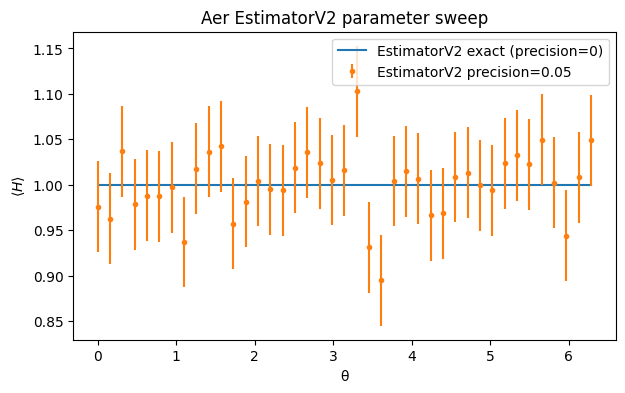

In [10]:
theta = Parameter("θ")
ansatz = QuantumCircuit(2)
ansatz.ry(theta, 0); ansatz.cx(0, 1)
H = SparsePauliOp.from_list([("ZZ", 1.0), ("XI", 0.5)])
thetas = np.linspace(0, 2 * np.pi, 41)

exact_est = AerEstimator()                                   # precision 0 -> exact
shot_est = AerEstimator(options={"default_precision": 0.05, "run_options": {"seed": 1}})

ev_exact = exact_est.run([(ansatz, H, thetas)]).result()[0].data.evs
pub_res = shot_est.run([(ansatz, H, thetas)]).result()[0]
ev_shot, ev_std = pub_res.data.evs, pub_res.data.stds

plt.figure(figsize=(7, 4))
plt.plot(thetas, ev_exact, label="EstimatorV2 exact (precision=0)")
plt.errorbar(thetas, ev_shot, yerr=ev_std, fmt="o", ms=3, label="EstimatorV2 precision=0.05")
plt.xlabel("θ"); plt.ylabel(r"$\langle H \rangle$"); plt.legend(); plt.title("Aer EstimatorV2 parameter sweep")
plt.show()

## 7. Noise models

`qiskit_aer.noise` builds `NoiseModel` objects from quantum error channels [[5]](https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html), [[12]](https://qiskit.github.io/qiskit-aer/apidocs/aer_noise.html):

* `depolarizing_error(p, n_qubits)`: with probability `p`, the state becomes the maximally mixed state.
* `thermal_relaxation_error(T1, T2, gate_time)`: amplitude damping and dephasing from $T_1$ and $T_2$.
* `ReadoutError([[P(0|0), P(1|0)], [P(0|1), P(1|1)]])`: a classical bit flip at measurement.
* Other channels: `pauli_error`, `amplitude_damping_error`, `phase_damping_error`, `coherent_unitary_error`, `kraus_error`, ...

`add_all_qubit_quantum_error` attaches an error to a gate on all qubits. `add_quantum_error` attaches it on specific qubits.
Pass the model to `AerSimulator(noise_model=...)`.

In [11]:
from qiskit_aer.noise import (NoiseModel, depolarizing_error, thermal_relaxation_error, ReadoutError)

# Parameters
p1, p2 = 0.002, 0.02                 # depolarizing probabilities (1q, 2q)
T1, T2 = 50e3, 70e3                  # ns  (T1 = 50 us, T2 = 70 us)
t_1q, t_2q, t_meas = 50, 300, 1000   # gate / measurement durations in ns

# Build the channels; compose() chains two errors on the same gate into one channel
err_1q = depolarizing_error(p1, 1).compose(thermal_relaxation_error(T1, T2, t_1q))
err_2q = depolarizing_error(p2, 2).compose(
    thermal_relaxation_error(T1, T2, t_2q).expand(thermal_relaxation_error(T1, T2, t_2q)))
err_meas = thermal_relaxation_error(T1, T2, t_meas)

nm = NoiseModel()
nm.add_all_qubit_quantum_error(err_1q, ["sx", "x", "h"])
nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["rz"])   # virtual Z: depolarizing only
nm.add_all_qubit_quantum_error(err_2q, ["cx"])
nm.add_all_qubit_quantum_error(err_meas, ["measure"])

# Readout error: 2% chance 0->1, 5% chance 1->0
nm.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.05, 0.95]]))

print(nm)

NoiseModel:
  Basis gates: ['cx', 'h', 'id', 'rz', 'sx', 'x']
  Instructions with noise: ['x', 'cx', 'rz', 'sx', 'h', 'measure']
  All-qubits errors: ['sx', 'x', 'h', 'rz', 'cx', 'measure']


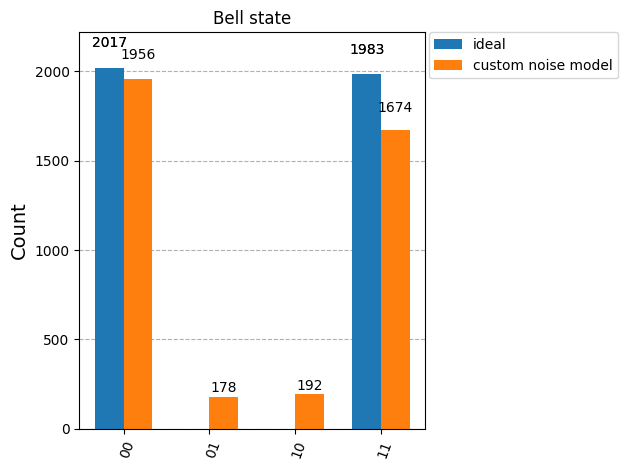

In [12]:
noisy_sim = AerSimulator(noise_model=nm)
ideal_sim = AerSimulator()
tb = transpile(bell, basis_gates=nm.basis_gates)   # no coupling map: all-to-all
counts_ideal = ideal_sim.run(tb, shots=4000, seed_simulator=2).result().get_counts()
counts_noisy = noisy_sim.run(tb, shots=4000, seed_simulator=2).result().get_counts()
plot_histogram([counts_ideal, counts_noisy], legend=["ideal", "custom noise model"], title="Bell state")

## 8. `NoiseModel.from_backend` with a fake IBM backend

`qiskit_ibm_runtime.fake_provider` contains snapshots of real IBM devices [[13]](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/fake-provider). A snapshot includes the coupling map, gate errors, $T_1$/$T_2$ and readout errors.
There are two ways to use a snapshot in Aer [[4]](https://qiskit.github.io/qiskit-aer/tutorials/2_device_noise_simulation.html):

* `NoiseModel.from_backend(fake_backend)`: only the noise model.
* `AerSimulator.from_backend(fake_backend)`: a simulator with the noise model, **and** the coupling map and basis gates of the device.

In [13]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

fake = FakeManilaV2()
print(fake.name, "| qubits:", fake.num_qubits, "| basis:", fake.operation_names)

nm_fake = NoiseModel.from_backend(fake)
print(nm_fake)

fake_sim = AerSimulator.from_backend(fake)
print("simulator:", fake_sim)

fake_manila | qubits: 5 | basis: ['switch_case', 'for_loop', 'x', 'cx', 'reset', 'rz', 'delay', 'sx', 'if_else', 'id', 'measure']
NoiseModel:
  Basis gates: ['cx', 'delay', 'for_loop', 'id', 'if_else', 'measure', 'reset', 'rz', 'switch_case', 'sx', 'x']
  Instructions with noise: ['x', 'cx', 'reset', 'sx', 'id', 'measure']
  Qubits with noise: [0, 1, 2, 3, 4]
  Specific qubit errors: [('x', (0,)), ('x', (1,)), ('x', (2,)), ('x', (3,)), ('x', (4,)), ('cx', (0, 1)), ('cx', (1, 0)), ('cx', (1, 2)), ('cx', (2, 1)), ('cx', (2, 3)), ('cx', (3, 2)), ('cx', (3, 4)), ('cx', (4, 3)), ('reset', (0,)), ('reset', (1,)), ('reset', (2,)), ('reset', (3,)), ('reset', (4,)), ('sx', (0,)), ('sx', (1,)), ('sx', (2,)), ('sx', (3,)), ('sx', (4,)), ('id', (0,)), ('id', (1,)), ('id', (2,)), ('id', (3,)), ('id', (4,)), ('measure', (0,)), ('measure', (1,)), ('measure', (2,)), ('measure', (3,)), ('measure', (4,))]


simulator: AerSimulator('aer_simulator_from(fake_manila)'
             noise_model=<NoiseModel on ['x', 'cx', 'reset', 'sx', 'id', 'measure']>)


## 9. Noisy vs ideal GHZ states

We prepare GHZ states $(|0\dots0\rangle + |1\dots1\rangle)/\sqrt 2$ of increasing size with the FakeManila noise model.
We compare them with the ideal result. We use two figures of merit:

* **Success probability** $P(0\dots0) + P(1\dots1)$, from sampling.
* **GHZ fidelity** $F = \langle GHZ|\rho|GHZ\rangle$, computed exactly with the `density_matrix` method and `save_density_matrix`.

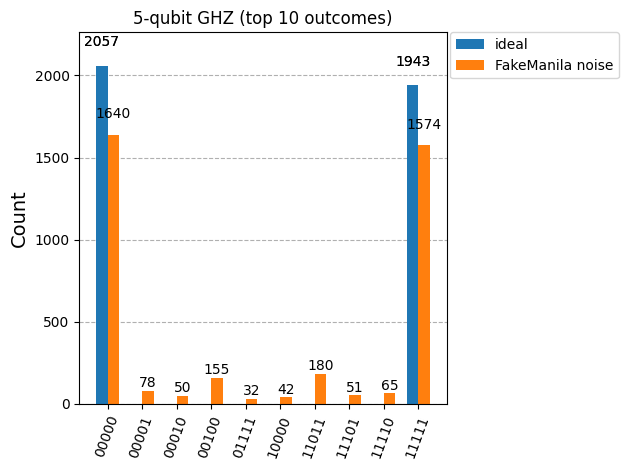

In [14]:
from qiskit.quantum_info import state_fidelity

def ghz(n, measure=True):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    if measure:
        qc.measure_all()
    return qc

# Sampling comparison for 5 qubits
g5 = transpile(ghz(5), fake_sim, optimization_level=1, seed_transpiler=1)
c_ideal = AerSimulator().run(g5, shots=4000, seed_simulator=3).result().get_counts()
c_noisy = fake_sim.run(g5, shots=4000, seed_simulator=3).result().get_counts()
top = sorted(c_noisy, key=c_noisy.get, reverse=True)[:10]
plot_histogram([{k: c_ideal.get(k, 0) for k in top}, {k: c_noisy[k] for k in top}],
               legend=["ideal", "FakeManila noise"], title="5-qubit GHZ (top 10 outcomes)")

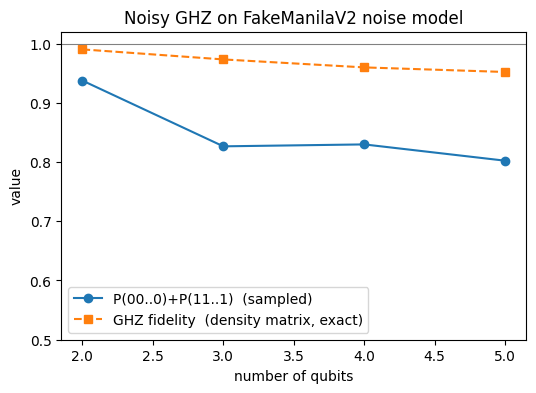

n=2: success=0.938  fidelity=0.990
n=3: success=0.827  fidelity=0.973
n=4: success=0.830  fidelity=0.960
n=5: success=0.802  fidelity=0.952


In [15]:
dm_sim = AerSimulator.from_backend(fake, method="density_matrix")
ns = range(2, 6)
succ, fid = [], []
for n in ns:
    # sampling success probability
    t = transpile(ghz(n), fake_sim, optimization_level=1, seed_transpiler=1)
    c = fake_sim.run(t, shots=4000, seed_simulator=4).result().get_counts()
    succ.append((c.get("0" * n, 0) + c.get("1" * n, 0)) / 4000)

    # exact fidelity: save the density matrix of the n *logical* qubits
    qc = ghz(n, measure=False)
    t = transpile(qc, dm_sim, optimization_level=1, seed_transpiler=1)
    phys = [t.layout.final_index_layout()[i] for i in range(n)]    # where logical qubits ended up
    t.save_density_matrix(qubits=phys, label="rho")
    rho = dm_sim.run(t).result().data(0)["rho"]
    fid.append(state_fidelity(rho, Statevector(qc)))

plt.figure(figsize=(6, 4))
plt.plot(list(ns), succ, "o-", label="P(00..0)+P(11..1)  (sampled)")
plt.plot(list(ns), fid, "s--", label="GHZ fidelity  (density matrix, exact)")
plt.axhline(1, color="gray", lw=0.8)
plt.xlabel("number of qubits"); plt.ylabel("value"); plt.ylim(0.5, 1.02)
plt.title("Noisy GHZ on FakeManilaV2 noise model"); plt.legend(); plt.show()
for n, s, f in zip(ns, succ, fid):
    print(f"n={n}: success={s:.3f}  fidelity={f:.3f}")

The fidelity is lower than the success probability.
The fidelity also measures the *coherence* between $|0\dots0\rangle$ and $|1\dots1\rangle$.
Sampling in the Z basis cannot detect a loss of this coherence.

## 10. Large Clifford circuits: stabilizer and MPS methods

A statevector of 100 qubits needs $2^{100}\times 16$ bytes. No computer has this much memory.
Two Aer methods can simulate such sizes when the circuit has structure:

* **stabilizer**: any Clifford circuit. The cost is polynomial in $n$ (Gottesman–Knill theorem).
* **matrix_product_state** (MPS): the cost grows with the entanglement, not with $n$ [[6]](https://qiskit.github.io/qiskit-aer/tutorials/7_matrix_product_state_method.html). The entanglement sets the bond dimension $\chi$ of the MPS. A GHZ state has $\chi=2$.

Below we simulate a 100-qubit GHZ state, and a 60-qubit layered random Clifford circuit with linear connectivity.

In [16]:
n = 100
big_ghz = ghz(n)
for method in ["stabilizer", "matrix_product_state"]:
    s = AerSimulator(method=method)
    t0 = time.perf_counter()
    c = s.run(big_ghz, shots=1000, seed_simulator=1).result().get_counts()
    dt = time.perf_counter() - t0
    print(f"{method:22s} {n} qubits: {len(c)} distinct outcomes, "
          f"all-0: {c.get('0'*n, 0)}, all-1: {c.get('1'*n, 0)}  ({dt:.2f} s)")

stabilizer             100 qubits: 2 distinct outcomes, all-0: 483, all-1: 517  (0.20 s)


matrix_product_state   100 qubits: 2 distinct outcomes, all-0: 483, all-1: 517  (0.32 s)


In [17]:
rng = np.random.default_rng(0)
def layered_clifford(n, layers):
    qc = QuantumCircuit(n)
    for layer in range(layers):
        for q in range(n):
            getattr(qc, rng.choice(["h", "s", "sdg", "x", "id"]))(q)
        for q in range(layer % 2, n - 1, 2):
            qc.cx(q, q + 1)
    return qc

n, layers = 60, 8
cl = layered_clifford(n, layers)
# expectation values of nearest-neighbour Z_i Z_{i+1}; for a stabilizer state each is 0 or +-1
for q in range(n - 1):
    cl.save_expectation_value(SparsePauliOp("ZZ"), qubits=[q, q + 1], label=f"ZZ_{q}")
cl.measure_all()

evs = {}
for method in ["stabilizer", "matrix_product_state"]:
    s = AerSimulator(method=method)
    t0 = time.perf_counter()
    r = s.run(cl, shots=200, seed_simulator=1).result()
    dt = time.perf_counter() - t0
    evs[method] = np.array([r.data(0)[f"ZZ_{q}"] for q in range(n - 1)])
    print(f"{method:22s} {n}q x {layers} layers: {len(r.get_counts())} distinct outcomes in 200 shots ({dt:.2f} s)")

print("<Z_i Z_i+1> (stabilizer):", np.round(evs["stabilizer"]).astype(int))
print("methods agree:", np.allclose(evs["stabilizer"], evs["matrix_product_state"], atol=1e-8))

stabilizer             60q x 8 layers: 200 distinct outcomes in 200 shots (0.02 s)
matrix_product_state   60q x 8 layers: 200 distinct outcomes in 200 shots (0.05 s)
<Z_i Z_i+1> (stabilizer): [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0
  0  0  0  0  0  0  0  0  0  0  0]
methods agree: True


Both methods give the same result.
For MPS, `matrix_product_state_max_bond_dimension` and `matrix_product_state_truncation_threshold` reduce the cost at the price of accuracy [[6]](https://qiskit.github.io/qiskit-aer/tutorials/7_matrix_product_state_method.html).
`save_matrix_product_state()` returns the MPS tensors.
The MPS method also works for **non-Clifford** circuits. The stabilizer method does not.

In [18]:
n = 40
qc = QuantumCircuit(n)
for q in range(n):
    qc.ry(0.3 + 0.01 * q, q)
for q in range(n - 1):
    qc.cx(q, q + 1)
    qc.rz(0.2, q + 1)
qc.save_matrix_product_state(label="mps")
qc.save_expectation_value(SparsePauliOp("Z" * n), qubits=list(range(n)), label="Zall")

mps_sim = AerSimulator(method="matrix_product_state", matrix_product_state_max_bond_dimension=16)
r = mps_sim.run(qc).result()
gammas, lambdas = r.data(0)["mps"]
print(f"{n}-qubit non-Clifford circuit: <Z...Z> = {r.data(0)['Zall']:.4f}")
print("bond dimensions:", [len(l) for l in lambdas])

40-qubit non-Clifford circuit: <Z...Z> = 0.0617
bond dimensions: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


## 11. Performance options

Pass options to the constructor (`AerSimulator(**opts)`), to `set_options`, or to `run(...)` [[9]](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html).

**CPU and general options** [[7]](https://qiskit.github.io/qiskit-aer/howtos/parallel.html)

| option | meaning |
|---|---|
| `max_parallel_threads` | total number of OpenMP threads (0 = all cores) |
| `max_parallel_experiments` | number of circuits that run in parallel |
| `max_parallel_shots` | number of shots that run in parallel (noisy circuits) |
| `max_memory_mb` | memory limit for the state |
| `precision` | `"double"` (default) or `"single"`. Single precision uses half the memory, with an error of about 1e-7 |
| `fusion_enable`, `fusion_max_qubit`, `fusion_threshold` | gate fusion: merge consecutive gates into larger unitaries. For the statevector method it is on from 14 qubits by default |
| `statevector_parallel_threshold` | minimum number of qubits before Aer parallelizes one state |
| `blocking_enable`, `blocking_qubits` | cache blocking. Also used to split a state into chunks for multiple GPUs or MPI |

**GPU options** (`device="GPU"`, needs a GPU build of Aer, as in this container) [[8]](https://qiskit.github.io/qiskit-aer/howtos/running_gpu.html), [[9]](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html)

| option | meaning |
|---|---|
| `cuStateVec_enable=True` | use the cuStateVec kernels of NVIDIA cuQuantum [[2]](https://docs.nvidia.com/cuda/cuquantum/latest/custatevec/index.html) |
| `batched_shots_gpu=True` | run the shots of noisy or dynamic circuits as a batch of states on the GPU, not one after another |
| `batched_shots_gpu_max_qubits` | maximum number of qubits for batched shots (default 16) |
| `shot_branching_enable` | split the state only at measurements or noise, so that shots share work |
| `target_gpus` | list of GPU indices to use |
| `blocking_enable=True, blocking_qubits=k` | split large states across multiple GPUs |

Example GPU configuration (it runs only if a GPU is available, see section 4):

```python
sim = AerSimulator(method="statevector", device="GPU",
                   cuStateVec_enable=True, batched_shots_gpu=True, precision="single")
```

Below we time a 20-qubit random circuit with different options. On a GPU node, the cell also runs the GPU with cuStateVec.
The `time_taken` field in the result metadata is the timing measured by the simulator.

default               158.0 ms | threads=12 fusion=True


1 thread             1539.4 ms | threads=1 fusion=True


8 threads             204.9 ms | threads=8 fusion=True


no fusion             174.3 ms | threads=12 fusion=None


single precision      393.5 ms | threads=12 fusion=True
GPU + cuStateVec       17.5 ms | threads=12 fusion=True
default            fidelity vs default: 1.00000000
1 thread           fidelity vs default: 1.00000000
8 threads          fidelity vs default: 1.00000000
no fusion          fidelity vs default: 1.00000000
single precision   fidelity vs default: 0.99999992
GPU + cuStateVec   fidelity vs default: 1.00000000


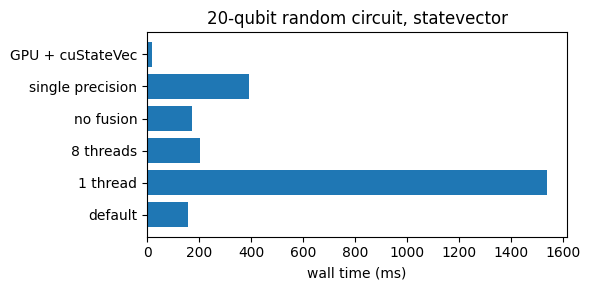

In [19]:
from qiskit.circuit.random import random_circuit

nq = 20
rc = random_circuit(nq, depth=12, max_operands=2, seed=7)
rc.save_statevector()
base = AerSimulator(method="statevector")
trc = transpile(rc, base, optimization_level=0)

configs = {
    "default":            {},
    "1 thread":           {"max_parallel_threads": 1},
    "8 threads":          {"max_parallel_threads": 8},
    "no fusion":          {"fusion_enable": False},
    "single precision":   {"precision": "single"},
}
if device == "GPU":
    configs["GPU + cuStateVec"] = {"device": "GPU", "cuStateVec_enable": True}

timings, states = {}, {}
for name, opts in configs.items():
    s = AerSimulator(method="statevector", **opts)
    s.run(trc).result()                               # warm-up run (not timed)
    t0 = time.perf_counter()
    r = s.run(trc).result()
    timings[name] = time.perf_counter() - t0
    states[name] = np.asarray(r.get_statevector())
    md_ = r.results[0].metadata
    print(f"{name:18s} {timings[name]*1e3:8.1f} ms | threads={md_.get('parallel_state_update')} "
          f"fusion={md_.get('fusion', {}).get('applied')}")

ref = states["default"]
for name, st in states.items():
    print(f"{name:18s} fidelity vs default: {abs(np.vdot(ref, st))**2:.8f}")

plt.figure(figsize=(6, 3))
plt.barh(list(timings), [1e3 * v for v in timings.values()])
plt.xlabel("wall time (ms)"); plt.title(f"{nq}-qubit random circuit, statevector")
plt.tight_layout(); plt.show()

Results of the run above (the numbers depend on the node and on the number of allocated cores):

* **Threads**: on this node, the default run used 12 threads (`threads=12`) and took 158.0 ms. This is the fastest CPU configuration. One thread took 1539.4 ms, and 8 threads took 204.9 ms. Set `max_parallel_threads` (or `OMP_NUM_THREADS`) to the number of cores of your job allocation.
* **Fusion**: gate fusion gives a small gain. Without fusion, the run took 174.3 ms instead of 158.0 ms.
* **Single precision**: it uses half the memory, and the fidelity is 0.99999992. On this CPU it was slower (393.5 ms).
* **GPU with cuStateVec**: 17.5 ms, about 9 times faster than the default CPU run.

## 12. Summary and references

* `AerSimulator` is a `BackendV2`. `method` selects the simulation method, and `device` selects CPU or GPU.
* `seed_simulator` (or the `seed` of the primitives) makes results reproducible.
* Save instructions (`save_statevector`, `save_expectation_value`, `save_density_matrix`, ...) give exact simulator data without sampling.
* `qiskit_aer.primitives.SamplerV2` and `EstimatorV2` run primitive-based code on Aer, with or without noise.
* Build noise models from channels (`depolarizing_error`, `thermal_relaxation_error`, `ReadoutError`), or import them from device snapshots with `NoiseModel.from_backend` or `AerSimulator.from_backend`.
* The stabilizer and MPS methods simulate circuits with 100 or more qubits when the circuits are Clifford or weakly entangled.

### References

1. Qiskit Aer: Getting started. <https://qiskit.github.io/qiskit-aer/getting_started.html>
2. NVIDIA cuQuantum documentation: cuStateVec. <https://docs.nvidia.com/cuda/cuquantum/latest/custatevec/index.html>
3. Qiskit Aer tutorial: Simulators. <https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html>
4. Qiskit Aer tutorial: Device backend noise model simulations. <https://qiskit.github.io/qiskit-aer/tutorials/2_device_noise_simulation.html>
5. Qiskit Aer tutorial: Building noise models. <https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html>
6. Qiskit Aer tutorial: Matrix product state simulation method. <https://qiskit.github.io/qiskit-aer/tutorials/7_matrix_product_state_method.html>
7. Qiskit Aer how-to: Running with threadpool. <https://qiskit.github.io/qiskit-aer/howtos/parallel.html>
8. Qiskit Aer how-to: Running with multiple GPUs and/or multiple nodes. <https://qiskit.github.io/qiskit-aer/howtos/running_gpu.html>
9. Qiskit Aer API reference: `AerSimulator` (methods, devices, GPU and cuStateVec options). <https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html>
10. Qiskit Aer contributing guide, section "Building with GPU support". <https://github.com/Qiskit/qiskit-aer/blob/main/CONTRIBUTING.md>
11. Qiskit Aer API reference: `qiskit_aer.primitives`. <https://qiskit.github.io/qiskit-aer/apidocs/aer_primitives.html>
12. Qiskit Aer API reference: `qiskit_aer.noise`. <https://qiskit.github.io/qiskit-aer/apidocs/aer_noise.html>
13. Qiskit IBM Runtime API reference: `fake_provider`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/fake-provider>